# Glucose Prediction — Model Evaluation

## Objective

Evaluate the trained Random Forest model for predicting glucose levels approximately **30 minutes into the future**.

## Evaluation Areas

1. Overall model performance
2. Actual vs Predicted glucose
3. Prediction error distribution
4. Glucose-range performance
5. Patient-wise performance
6. Detailed error analysis

## Model

Random Forest Regressor

## Evaluation Metrics

- MAE — Mean Absolute Error
- RMSE — Root Mean Squared Error
- R² — Coefficient of Determination

The model was trained using a **patient-wise chronological train/test split** to reduce temporal data leakage.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
DATA_PATH = "../data/processed/ml_dataset.csv"
MODEL_PATH = "../models/random_forest_glucose_model.pkl"
FEATURE_PATH = "../models/feature_columns.pkl"

print("Paths defined.")
print("Dataset:", DATA_PATH)
print("Model:", MODEL_PATH)
print("Features:", FEATURE_PATH)

Paths defined.
Dataset: ../data/processed/ml_dataset.csv
Model: ../models/random_forest_glucose_model.pkl
Features: ../models/feature_columns.pkl


In [3]:
df = pd.read_csv(DATA_PATH)

df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (65499, 21)


In [4]:
model = joblib.load(MODEL_PATH)
feature_columns = joblib.load(FEATURE_PATH)

print("Model loaded successfully.")
print("Model type:", type(model).__name__)

print("\nNumber of features:", len(feature_columns))
print("\nFeatures:")
for feature in feature_columns:
    print("-", feature)

Model loaded successfully.
Model type: RandomForestRegressor

Number of features: 18

Features:
- glucose_value
- glucose_lag_1
- glucose_lag_2
- glucose_lag_3
- glucose_lag_6
- glucose_change_5min
- glucose_change_15min
- meal_carbs
- bolus_dose
- basal_value
- temp_basal_value
- exercise_duration
- exercise_intensity
- sleep_duration_hours
- sleep_quality
- finger_stick_value
- hour
- day_of_week


In [5]:
print("Dataset shape:", df.shape)

print("\nNumber of patients:", df["Patient"].nunique())

print("\nPatients:")
for patient in df["Patient"].unique():
    print("-", patient)

print("\nMissing values:", df.isnull().sum().sum())

print(
    "\nDuplicate Patient + Timestamp records:",
    df.duplicated(
        subset=["Patient", "timestamp"]
    ).sum()
)

Dataset shape: (65499, 21)

Number of patients: 6

Patients:
- 540-ws-training
- 544-ws-training
- 552-ws-training
- 567-ws-training
- 584-ws-training
- 596-ws-training

Missing values: 0

Duplicate Patient + Timestamp records: 0


In [6]:
train_parts = []
test_parts = []

for patient in df["Patient"].unique():

    patient_df = df[
        df["Patient"] == patient
    ].sort_values("timestamp")

    split_index = int(len(patient_df) * 0.80)

    train_patient = patient_df.iloc[:split_index]
    test_patient = patient_df.iloc[split_index:]

    train_parts.append(train_patient)
    test_parts.append(test_patient)

train_df = pd.concat(
    train_parts
).sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

test_df = pd.concat(
    test_parts
).sort_values(
    ["Patient", "timestamp"]
).reset_index(drop=True)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (52396, 21)
Testing shape: (13103, 21)


In [7]:
print("Chronological split verification:\n")

for patient in df["Patient"].unique():

    train_patient = train_df[
        train_df["Patient"] == patient
    ]

    test_patient = test_df[
        test_df["Patient"] == patient
    ]

    train_end = train_patient["timestamp"].max()
    test_start = test_patient["timestamp"].min()

    print(f"Patient: {patient}")
    print(f"  Training end : {train_end}")
    print(f"  Testing start: {test_start}")
    print(
        f"  Valid split  : "
        f"{train_end < test_start}"
    )
    print()

Chronological split verification:

Patient: 540-ws-training
  Training end : 2027-06-23 22:14:15
  Testing start: 2027-06-23 22:19:15
  Valid split  : True

Patient: 544-ws-training
  Training end : 2027-06-16 01:19:00
  Testing start: 2027-06-16 01:24:00
  Valid split  : True

Patient: 552-ws-training
  Training end : 2025-05-17 07:01:54
  Testing start: 2025-05-17 07:06:54
  Valid split  : True

Patient: 567-ws-training
  Training end : 2027-02-03 03:39:02
  Testing start: 2027-02-03 03:44:02
  Valid split  : True

Patient: 584-ws-training
  Training end : 2025-06-19 04:32:00
  Testing start: 2025-06-19 04:37:00
  Valid split  : True

Patient: 596-ws-training
  Training end : 2027-05-16 04:47:00
  Testing start: 2027-05-16 04:52:00
  Valid split  : True



In [8]:
X_test = test_df[feature_columns]
y_test = test_df["target_glucose_30min"]

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nNumber of features:", X_test.shape[1])

X_test shape: (13103, 18)
y_test shape: (13103,)

Number of features: 18


In [9]:
predictions = model.predict(X_test)

print("Predictions generated successfully.")

print("\nNumber of predictions:", len(predictions))

print("\nFirst 10 predictions:")
print(predictions[:10])

Predictions generated successfully.

Number of predictions: 13103

First 10 predictions:
[127.055 123.39  133.895 135.13  120.9   130.255 127.575 129.315 116.715
 105.425]


In [10]:
mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

r2 = r2_score(
    y_test,
    predictions
)

print("Random Forest Evaluation")
print("=" * 35)

print(f"MAE  : {mae:.4f} mg/dL")
print(f"RMSE : {rmse:.4f} mg/dL")
print(f"R²   : {r2:.4f}")

Random Forest Evaluation
MAE  : 17.5745 mg/dL
RMSE : 26.4067 mg/dL
R²   : 0.8155


In [11]:
evaluation_summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R²"
    ],
    "Value": [
        mae,
        rmse,
        r2
    ]
})

evaluation_summary

,Metric,Value
0,MAE,17.574544
1,RMSE,26.406743
2,R²,0.815545


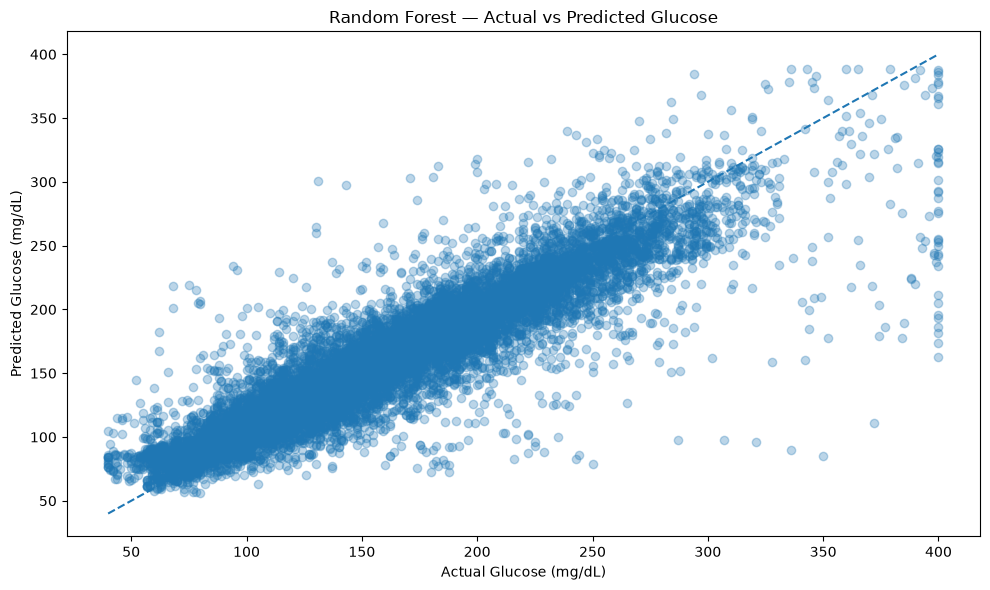

In [12]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.3
)

min_value = min(
    y_test.min(),
    predictions.min()
)

max_value = max(
    y_test.max(),
    predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Glucose (mg/dL)")
plt.ylabel("Predicted Glucose (mg/dL)")
plt.title(
    "Random Forest — Actual vs Predicted Glucose"
)

plt.tight_layout()
plt.show()

In [13]:
evaluation_df = test_df[
    ["Patient", "timestamp", "glucose_value", "target_glucose_30min"]
].copy()

evaluation_df["predicted_glucose"] = predictions

evaluation_df["error"] = (
    evaluation_df["target_glucose_30min"]
    - evaluation_df["predicted_glucose"]
)

evaluation_df["absolute_error"] = (
    evaluation_df["error"].abs()
)

evaluation_df.head()

,Patient,timestamp,glucose_value,target_glucose_30min,predicted_glucose,error,absolute_error
0,540-ws-training,2027-06-23 22:19:15,146,133.0,127.055,5.945,5.945
1,540-ws-training,2027-06-23 22:24:15,143,132.0,123.390,8.610,8.610
2,540-ws-training,2027-06-23 22:29:15,141,127.0,133.895,-6.895,6.895
3,540-ws-training,2027-06-23 22:34:15,139,122.0,135.130,-13.130,13.130
4,540-ws-training,2027-06-23 22:39:15,135,121.0,120.900,0.100,0.100


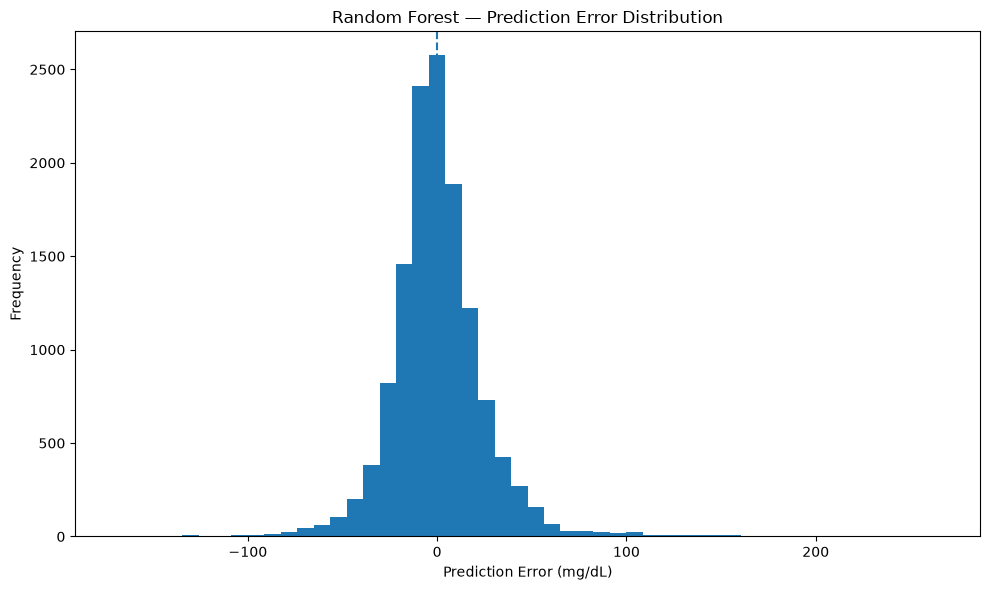

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(
    evaluation_df["error"],
    bins=50
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Prediction Error (mg/dL)")
plt.ylabel("Frequency")
plt.title(
    "Random Forest — Prediction Error Distribution"
)

plt.tight_layout()
plt.show()

In [15]:
print("Prediction Error Statistics")
print("=" * 35)

print(
    evaluation_df["error"].describe()
)

Prediction Error Statistics
count    13103.000000
mean         0.647968
std         26.399800
min       -169.475417
25%        -12.512500
50%         -1.265000
75%         12.120000
max        265.055000
Name: error, dtype: float64


In [16]:
def glucose_range(value):

    if value < 70:
        return "Low"

    elif value < 140:
        return "Normal"

    elif value < 180:
        return "Elevated"

    else:
        return "High"


evaluation_df["glucose_range"] = (
    evaluation_df["target_glucose_30min"]
    .apply(glucose_range)
)

print(
    evaluation_df["glucose_range"]
    .value_counts()
)

glucose_range
High        4737
Normal      4676
Elevated    3255
Low          435
Name: count, dtype: int64


In [17]:
range_results = []

ranges = [
    "Low",
    "Normal",
    "Elevated",
    "High"
]

for glucose_range_name in ranges:

    subset = evaluation_df[
        evaluation_df["glucose_range"]
        == glucose_range_name
    ]

    if len(subset) == 0:
        continue

    range_mae = mean_absolute_error(
        subset["target_glucose_30min"],
        subset["predicted_glucose"]
    )

    range_rmse = np.sqrt(
        mean_squared_error(
            subset["target_glucose_30min"],
            subset["predicted_glucose"]
        )
    )

    range_results.append({
        "Glucose Range": glucose_range_name,
        "Samples": len(subset),
        "MAE": range_mae,
        "RMSE": range_rmse
    })

range_results = pd.DataFrame(
    range_results
)

range_results

,Glucose Range,Samples,MAE,RMSE
0,Low,435,24.295735,30.594032
1,Normal,4676,14.281251,20.302566
2,Elevated,3255,14.108882,19.701718
3,High,4737,22.589628,34.194806


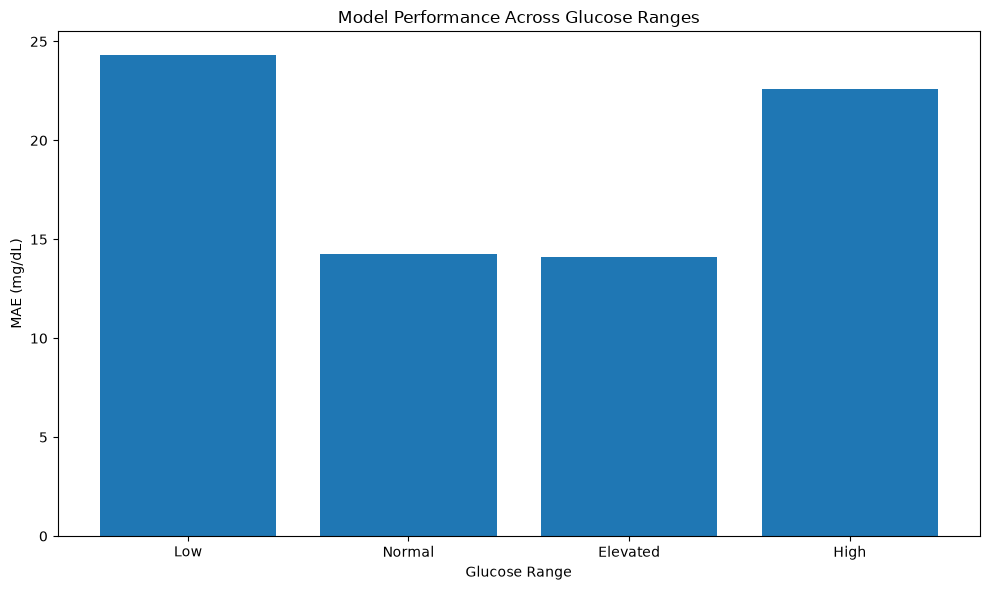

In [18]:
plt.figure(figsize=(10, 6))

plt.bar(
    range_results["Glucose Range"],
    range_results["MAE"]
)

plt.xlabel("Glucose Range")
plt.ylabel("MAE (mg/dL)")
plt.title(
    "Model Performance Across Glucose Ranges"
)

plt.tight_layout()
plt.show()

In [19]:
patient_results = []

for patient in evaluation_df["Patient"].unique():

    subset = evaluation_df[
        evaluation_df["Patient"] == patient
    ]

    patient_mae = mean_absolute_error(
        subset["target_glucose_30min"],
        subset["predicted_glucose"]
    )

    patient_rmse = np.sqrt(
        mean_squared_error(
            subset["target_glucose_30min"],
            subset["predicted_glucose"]
        )
    )

    patient_r2 = r2_score(
        subset["target_glucose_30min"],
        subset["predicted_glucose"]
    )

    patient_results.append({
        "Patient": patient,
        "Samples": len(subset),
        "MAE": patient_mae,
        "RMSE": patient_rmse,
        "R²": patient_r2
    })

patient_results = pd.DataFrame(
    patient_results
)

patient_results

,Patient,Samples,MAE,RMSE,R²
0,540-ws-training,2389,17.125121,22.751253,0.849802
1,544-ws-training,2124,13.766912,19.233711,0.843930
2,552-ws-training,1815,18.136626,23.834664,0.866212
3,567-ws-training,2171,18.820935,28.272505,0.797955
4,584-ws-training,2429,25.517142,39.643704,0.620714
5,596-ws-training,2175,11.203243,15.620247,0.891837


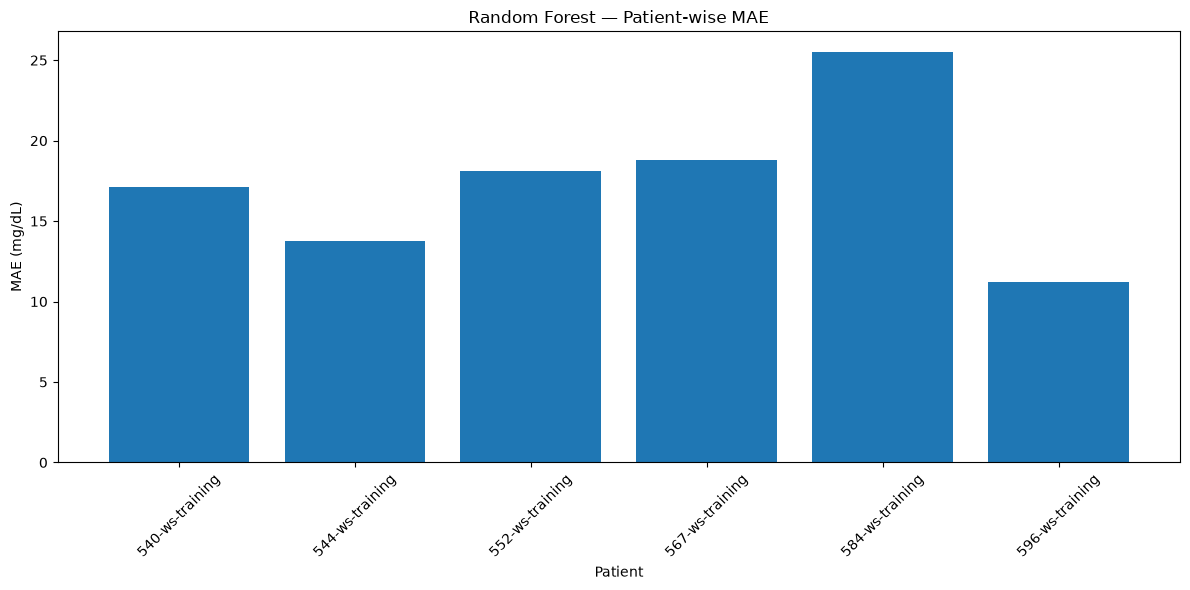

In [20]:
plt.figure(figsize=(12, 6))

plt.bar(
    patient_results["Patient"],
    patient_results["MAE"]
)

plt.xlabel("Patient")
plt.ylabel("MAE (mg/dL)")
plt.title(
    "Random Forest — Patient-wise MAE"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

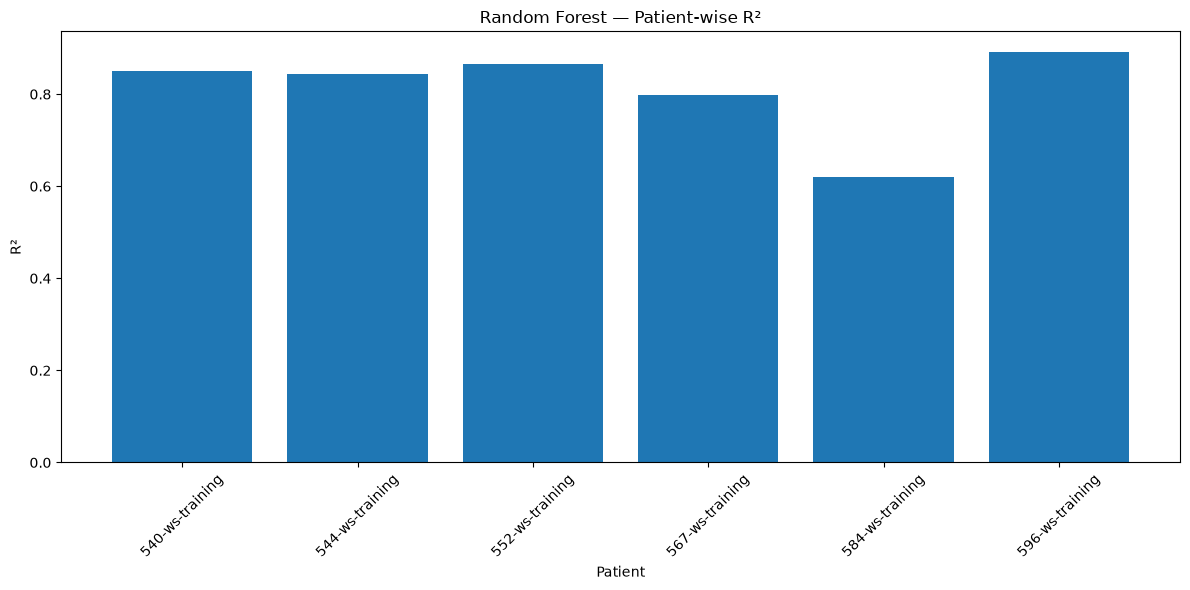

In [21]:
plt.figure(figsize=(12, 6))

plt.bar(
    patient_results["Patient"],
    patient_results["R²"]
)

plt.xlabel("Patient")
plt.ylabel("R²")
plt.title(
    "Random Forest — Patient-wise R²"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Importance
0,glucose_value,0.819644
1,glucose_change_5min,0.047171
2,glucose_lag_6,0.015837
3,bolus_dose,0.014905
4,hour,0.013460
5,finger_stick_value,0.013364
6,glucose_change_15min,0.012914
7,meal_carbs,0.009967
8,sleep_duration_hours,0.008311
9,glucose_lag_2,0.007915


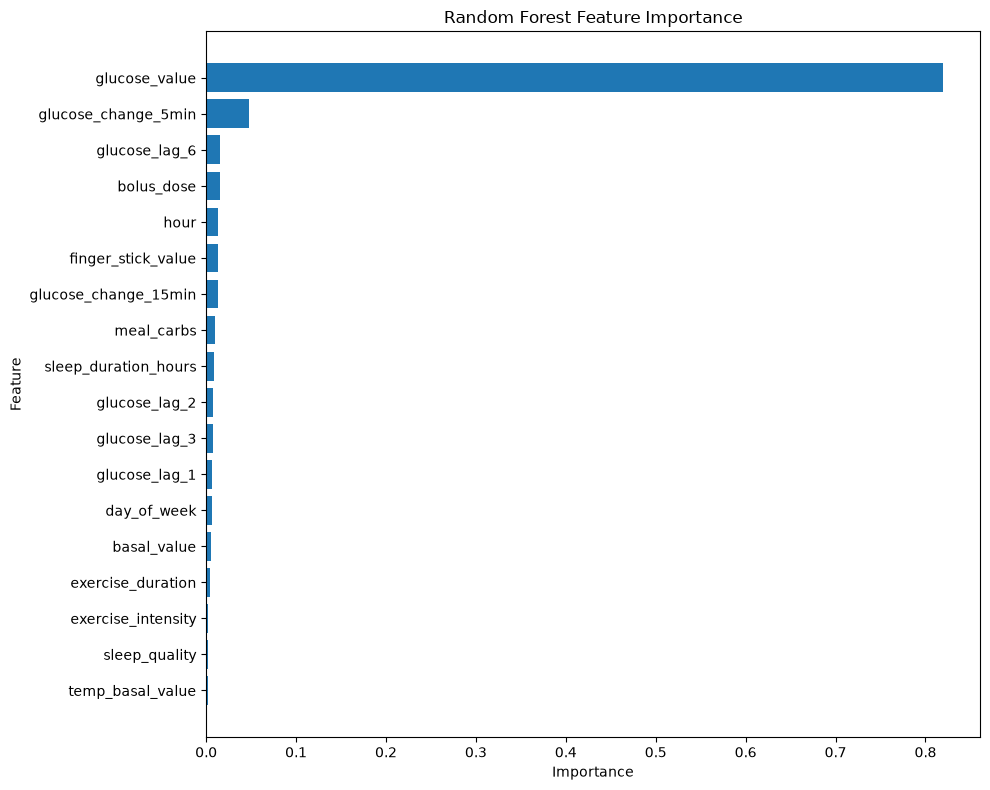

In [23]:
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(
    "Random Forest Feature Importance"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [24]:
largest_errors = evaluation_df.sort_values(
    "absolute_error",
    ascending=False
).head(20)

largest_errors[
    [
        "Patient",
        "timestamp",
        "glucose_value",
        "target_glucose_30min",
        "predicted_glucose",
        "error",
        "absolute_error",
        "glucose_range"
    ]
]

,Patient,timestamp,glucose_value,target_glucose_30min,predicted_glucose,error,absolute_error,glucose_range
10455,584-ws-training,2025-06-26 13:37:00,40,350.0,84.945000,265.055000,265.055000,High
6503,567-ws-training,2027-02-04 12:39:15,122,372.0,111.145000,260.855000,260.855000,High
10456,584-ws-training,2025-06-26 13:42:00,40,336.0,89.833333,246.166667,246.166667,High
10059,584-ws-training,2025-06-25 01:26:00,180,400.0,162.990000,237.010000,237.010000,High
10114,584-ws-training,2025-06-25 06:01:00,400,400.0,173.823161,226.176839,226.176839,High
10457,584-ws-training,2025-06-26 13:47:00,40,321.0,96.396667,224.603333,224.603333,High
6504,567-ws-training,2027-02-04 12:44:15,139,400.0,181.495000,218.505000,218.505000,High
10115,584-ws-training,2025-06-25 06:06:00,398,400.0,186.375411,213.624589,213.624589,High
10458,584-ws-training,2025-06-26 13:52:00,40,307.0,97.676667,209.323333,209.323333,High
10113,584-ws-training,2025-06-25 05:56:00,398,384.0,177.229994,206.770006,206.770006,High


In [25]:
mean_error = evaluation_df["error"].mean()

print(
    f"Mean prediction error: {mean_error:.4f} mg/dL"
)

if mean_error > 0:
    print(
        "The model tends to underpredict glucose "
        "slightly on average."
    )

elif mean_error < 0:
    print(
        "The model tends to overpredict glucose "
        "slightly on average."
    )

else:
    print(
        "The model has approximately zero average bias."
    )

Mean prediction error: 0.6480 mg/dL
The model tends to underpredict glucose slightly on average.


# Evaluation Summary

## Overall Performance

The Random Forest model achieved:

- MAE: approximately 17.57 mg/dL
- RMSE: approximately 26.41 mg/dL
- R²: approximately 0.8155

## Evaluation Method

The model was evaluated using a patient-wise chronological test set.

This approach ensures that earlier observations are used for training while later observations are reserved for testing, providing a more realistic simulation of future glucose prediction.

## Additional Analysis

The evaluation examined:

- Overall prediction accuracy
- Actual vs predicted glucose
- Prediction error distribution
- Glucose-range performance
- Patient-wise performance
- Feature importance
- Largest prediction errors
- Prediction bias

## Current Conclusion

Random Forest is currently the strongest baseline model among the evaluated models based primarily on RMSE and R².

Further improvement will be investigated through:

1. Hyperparameter tuning
2. Gradient boosting models
3. Advanced ensemble models
4. Detailed error analysis